<a href="https://colab.research.google.com/github/vigneshwaranmanikandan/data-science/blob/main/Naive_Bayes_Loan_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

In [6]:
train = pd.read_csv(r"/content/train_u6lujuX_CVtuZ9i.csv")
test = pd.read_csv(r"/content/test_Y3wMUE5_7gLdaTN.csv")

In [7]:
print(train.head())

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [8]:
print(train.shape)

(614, 13)


In [9]:
print(train.describe())

       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
count       614.000000         614.000000  592.000000         600.00000   
mean       5403.459283        1621.245798  146.412162         342.00000   
std        6109.041673        2926.248369   85.587325          65.12041   
min         150.000000           0.000000    9.000000          12.00000   
25%        2877.500000           0.000000  100.000000         360.00000   
50%        3812.500000        1188.500000  128.000000         360.00000   
75%        5795.000000        2297.250000  168.000000         360.00000   
max       81000.000000       41667.000000  700.000000         480.00000   

       Credit_History  
count      564.000000  
mean         0.842199  
std          0.364878  
min          0.000000  
25%          1.000000  
50%          1.000000  
75%          1.000000  
max          1.000000  


In [10]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None


In [11]:
print(train.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [13]:
print(train['Loan_Status'].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [14]:
x=train.drop(columns=['Loan_ID', 'Loan_Status'])
y=train['Loan_Status']

In [15]:
cat_cols = x.select_dtypes(include=['object']).columns
num_cols = x.select_dtypes(exclude=['object']).columns

In [18]:
num_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scalar', StandardScaler())])
cat_pipeline= Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),  ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

In [19]:
preprocessor = ColumnTransformer([('num',num_pipeline, num_cols),('cat',cat_pipeline, cat_cols)])

In [22]:
x_train, x_val, y_train, y_val = train_test_split(x,y, test_size=0.2, random_state=42,stratify=y)

In [24]:
model=Pipeline([('preprocess', preprocessor), ('classifier', GaussianNB())])

In [25]:
model.fit(x_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scalar',
                                                                   StandardScaler())]),
                                                  Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area'],
      dtype='object'))])),
                ('classifier', GaussianNB())])

In [26]:
y_pred = model.predict(x_val)

In [28]:
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy: ", accuracy * 100)

Accuracy:  84.5528455284553


In [29]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           N       0.88      0.58      0.70        38
           Y       0.84      0.96      0.90        85

    accuracy                           0.85       123
   macro avg       0.86      0.77      0.80       123
weighted avg       0.85      0.85      0.84       123



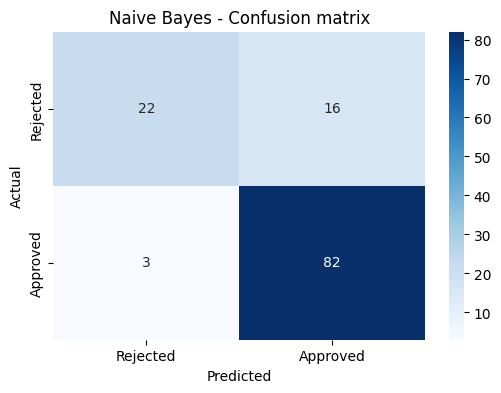

In [35]:
cm = confusion_matrix(y_val, y_pred, labels=['N', 'Y'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes - Confusion matrix')
plt.show()

In [37]:
x_test = test.drop(columns=['Loan_ID'])
final_model = Pipeline([('preprocess', preprocessor),('classifier', GaussianNB())])
final_model.fit(x, y)
test_predictions = final_model.predict(x_test)

In [42]:
submission = pd.DataFrame({'Loan_ID': test['Loan_ID'],'Loan_Status': test_predictions})
submission.to_csv('naive_bayes_loan_predictions.csv',index=False)

In [44]:
from google.colab import files
files.download('naive_bayes_loan_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>